In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

print("=====================================================================")
print("                 REPORTE: COMPARATIVA DE MODELOS")
print("=====================================================================\n")

# Datos recopilados de las evaluaciones Test y K-Fold de los cuadernos 03, 04 y 05
datos_comparativa = {
    'Modelo Evaluado': ['Regresión Lineal', 'Árbol de Decisión', 'Random Forest'],
    'Varianza Explicada (R2)': ['55.18 %', '79.45 %', '81.80 %'],
    'Error Absoluto Medio (MAE)': ['4.94 min', '3.34 min', '3.17 min'],
    'Estabilidad K-Fold (MAE Promedio)': ['4.97 min (+/- 0.05)', '3.31 min (+/- 0.03)', '3.17 min (+/- 0.03)']
}

df_reporte = pd.DataFrame(datos_comparativa)
df_reporte.set_index('Modelo Evaluado', inplace=True)

# Imprimir la tabla usando el motor nativo de visualización de Jupyter
display(df_reporte)

                 REPORTE: COMPARATIVA DE MODELOS



,Varianza Explicada (R2),Error Absoluto Medio (MAE),Estabilidad K-Fold (MAE Promedio)
Modelo Evaluado,,,
Regresión Lineal,55.18 %,4.94 min,4.97 min (+/- 0.05)
Árbol de Decisión,79.45 %,3.34 min,3.31 min (+/- 0.03)
Random Forest,81.80 %,3.17 min,3.17 min (+/- 0.03)


C:\Users\USUARIO\AppData\Local\Temp\ipykernel_11840\1521601056.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  grafico_r2 = sns.barplot(x=modelos, y=r2_valores, palette=['#ffb3ba', '#bae1ff', '#baffc9'], ax=ax[0])
C:\Users\USUARIO\AppData\Local\Temp\ipykernel_11840\1521601056.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  grafico_mae = sns.barplot(x=modelos, y=mae_valores, palette=['#ff9999', '#66b3ff', '#99ff99'], ax=ax[1])


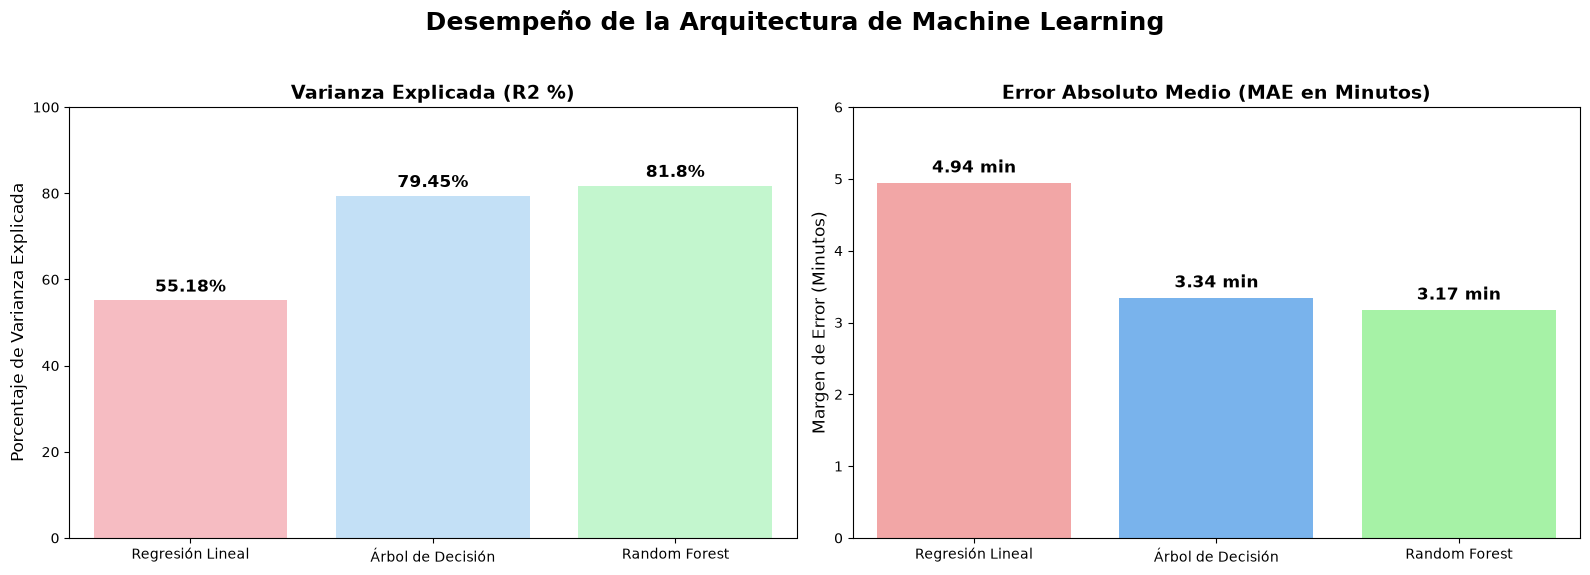


                          CONCLUSIÓN

Tras someter la arquitectura a pruebas de generalización (Validación Cruzada K-Fold),
determinamos que el modelo RANDOM FOREST es el algoritmo seleccionado para su despliegue a producción.

Justificación:
1. Minimización del Error: Redujo el MAE en un 35% frente a la Regresión Lineal base, estableciendo el
   margen de equivocación operativo en 3.17 minutos.
2. Capacidad de Comprensión: Alcanzó un R2 del 81.80%, demostrando la superioridad de los métodos de ensamble
   para descifrar relaciones no lineales complejas (como la interacción entre clima adverso y tráfico denso).
3. Estabilidad en Producción: La desviación estándar del K-Fold fue de +/- 0.03 minutos, demostrando
   que el Random Forest aprendió las reglas logísticas del negocio sin caer en Overfitting.


In [12]:
# Preparar datos para los gráficos
modelos = ['Regresión Lineal', 'Árbol de Decisión', 'Random Forest']
mae_valores = [4.94, 3.34, 3.17]
r2_valores = [55.18, 79.45, 81.80]

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Desempeño de la Arquitectura de Machine Learning', fontsize=18, fontweight='bold')

# --- Gráfico 1: Varianza Explicada (R2) ---
# Mayor es mejor (Queremos que las barras suban)
grafico_r2 = sns.barplot(x=modelos, y=r2_valores, palette=['#ffb3ba', '#bae1ff', '#baffc9'], ax=ax[0])
ax[0].set_title('Varianza Explicada (R2 %)', fontsize=14, fontweight='bold')
ax[0].set_ylabel('Porcentaje de Varianza Explicada', fontsize=12)
ax[0].set_ylim(0, 100)

for i, v in enumerate(r2_valores):
    grafico_r2.text(i, v + 2, f"{v}%", ha='center', fontsize=12, fontweight='bold')

# --- Gráfico 2: Error Absoluto Medio (MAE) ---
# Menor es mejor (Queremos que las barras bajen)
grafico_mae = sns.barplot(x=modelos, y=mae_valores, palette=['#ff9999', '#66b3ff', '#99ff99'], ax=ax[1])
ax[1].set_title('Error Absoluto Medio (MAE en Minutos)', fontsize=14, fontweight='bold')
ax[1].set_ylabel('Margen de Error (Minutos)', fontsize=12)
ax[1].set_ylim(0, 6)

for i, v in enumerate(mae_valores):
    grafico_mae.text(i, v + 0.15, f"{v} min", ha='center', fontsize=12, fontweight='bold')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# --- CONCLUSIÓN FINAL DEL PROYECTO ---
print("\n=====================================================================")
print("                          CONCLUSIÓN")
print("=====================================================================\n")
print("Tras someter la arquitectura a pruebas de generalización (Validación Cruzada K-Fold),")
print("determinamos que el modelo RANDOM FOREST es el algoritmo seleccionado para su despliegue a producción.\n")
print("Justificación:")
print("1. Minimización del Error: Redujo el MAE en un 35% frente a la Regresión Lineal base, estableciendo el")
print("   margen de equivocación operativo en 3.17 minutos.")
print("2. Capacidad de Comprensión: Alcanzó un R2 del 81.80%, demostrando la superioridad de los métodos de ensamble")
print("   para descifrar relaciones no lineales complejas (como la interacción entre clima adverso y tráfico denso).")
print("3. Estabilidad en Producción: La desviación estándar del K-Fold fue de +/- 0.03 minutos, demostrando")
print("   que el Random Forest aprendió las reglas logísticas del negocio sin caer en Overfitting.")